## Data Pipelines - Prefect - Example and Workshop
### Big Data Tools 
#### M.Sc. in Applied Analytics (coterminal course)
Fac. de Ingeniería -  Universidad de la Sabana<br>
Prof.: Hugo Franco, Ph.D.

In [1]:
import os
os.environ['OMP_NUM_THREADS'] = '1'  # prevent problems with KMeans and Prefect

from prefect import flow, task, get_run_logger
import pandas as pd
import numpy as np
import seaborn as sns
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score 
from kaggle import KaggleApi

# --- Configuration (single source of truth) ---
DOWNLOAD_DIRECTORY = Path('data/')
TARGET_DATASET = 'madhur321/world-bank-development-indicators-panel'
PANEL_FILENAME = 'wdi_country_year_panel.csv'
TARGET_YEAR = 2022

# --- Task: authenticate against Kaggle ---
@task(retries=3, retry_delay_seconds=10, name="Authenticate")
def api_authenticate() -> KaggleApi:
    logger = get_run_logger()
    try:
        api = KaggleApi()
        api.authenticate()
        logger.info("Kaggle authentication succeeded.")
        return api
    except Exception as e:
        logger.error(f"Kaggle authentication failed: {e}")
        raise

# --- Flow: download the dataset ---
@flow(name="extract-data")
def extract_data(
    download_path: str = str(DOWNLOAD_DIRECTORY),
    dataset_id: str = TARGET_DATASET,
) -> Path:
    logger = get_run_logger()
    path = Path(download_path)
    try:
        # Directory setup is a side effect — keep it inside the flow, not at import
        path.mkdir(parents=True, exist_ok=True)
        logger.info(f"Downloading dataset '{dataset_id}' to '{path}'...")
        kaggle_api = api_authenticate()
        kaggle_api.dataset_download_files(dataset_id, path=str(path), unzip=True)
        logger.info("Download completed successfully.")
        return path
    except Exception as e:
        logger.error(f"Data extraction failed: {e}")
        raise
    finally:
        logger.info("extract_data flow finished (with or without errors).")

download_path = extract_data()


17:13:34.318 | INFO    | Flow run 'platinum-bonobo' - Beginning flow run 'platinum-bonobo' for flow 'extract-data'

17:13:34.342 | INFO    | Flow run 'platinum-bonobo' - View at http://127.0.0.1:4200/runs/flow-run/6bb7a25f-6162-4769-8c4a-adff9896cad6

17:13:34.345 | INFO    | Flow run 'platinum-bonobo' - Downloading dataset 'madhur321/world-bank-development-indicators-panel' to 'data'...

17:13:34.381 | INFO    | Task run 'Authenticate-86a' - Kaggle authentication succeeded.

17:13:34.385 | INFO    | Task run 'Authenticate-86a' - Finished in state Completed()

Dataset URL: https://www.kaggle.com/datasets/madhur321/world-bank-development-indicators-panel


17:13:34.934 | INFO    | Flow run 'platinum-bonobo' - Download completed successfully.

17:13:34.936 | INFO    | Flow run 'platinum-bonobo' - extract_data flow finished (with or without errors).

17:13:35.349 | INFO    | Flow run 'platinum-bonobo' - Finished in state Completed()

In [2]:
df_wdi = pd.read_csv(DOWNLOAD_DIRECTORY / PANEL_FILENAME)
print(f"Raw panel loaded: {df_wdi.shape[0]} rows × {df_wdi.shape[1]} columns.")

# Snapshot of a single year so that each row corresponds to one country
df_countries = df_wdi[df_wdi['year'] == TARGET_YEAR].copy()
print(f"Year {TARGET_YEAR} snapshot: {df_countries.shape[0]} countries.")

# Interpretable indicators used for clustering
FEATURE_COLUMNS = [
    'gdp_per_capita_usd',      # economic output per person
    'life_expectancy',         # population health
    'energy_use_per_capita',   # energy / environmental pressure proxy
    'internet_users_pct',      # digital access
    'unemployment_pct',        # labour market
    'fertility_rate',          # demography
]

# Data cleansing: keep only countries with complete indicator coverage.
df_clustering = (
    df_countries[FEATURE_COLUMNS]
    .dropna()
    .reset_index(drop=True)
)
n_dropped = df_countries.shape[0] - df_clustering.shape[0]
print(f"Clustering frame: {df_clustering.shape[0]} complete countries "
      f"({n_dropped} dropped due to missing indicators).")


Raw panel loaded: 5425 rows × 41 columns.
Year 2022 snapshot: 217 countries.
Clustering frame: 134 complete countries (83 dropped due to missing indicators).


### Basic (Unsupervised) Machine Learning analytics method
 Determine, by clustering, a sound number of species within the wheat seed dataset

 Firstly, identify the less correlated pair of features and use them as the representation for the instances in the dataset

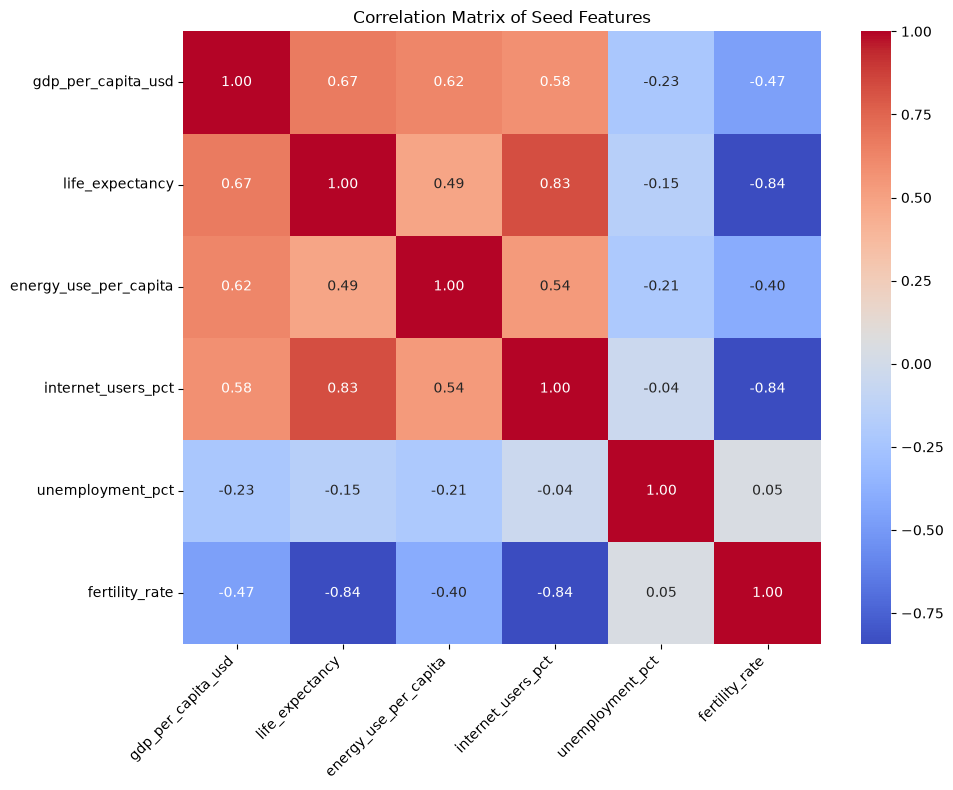

The lowest absolute correlation is 0.0389 between ('internet_users_pct', 'unemployment_pct')


In [3]:
# Calculate the correlation matrix.
correlation_matrix = df_clustering.corr()

# Plot a heatmap of the correlation matrix for visualization.
plt.figure(figsize=(10, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Seed Features')
plt.xticks(rotation=45, ha='right')
plt.yticks(rotation=0)
plt.tight_layout()
plt.savefig('correlation_heatmap.png')
plt.show()
plt.close()   # release the figure

# To find the lowest correlation, we need to ignore the diagonal (self-correlation) and look 
# for the smallest absolute value in the matrix (variable selection for K-Means analysis)
# 1. Convert to absolute values (strength matters, not direction)
abs_corr_matrix = correlation_matrix.abs()

# 2. "Unstack" the matrix into a long list of pairs
# This turns a [Variable x Variable] table into a [Variable Pair | Value] list
all_pairs = abs_corr_matrix.unstack()

# 3. Filter out the diagonal (where a variable correlates with itself)
# Since self-correlation is always 1.0, we just look for anything less than 1
unique_pairs = all_pairs[all_pairs < 1]

# 4. Find the smallest value and its labels
lowest_corr = unique_pairs.min()
lowest_corr_pair = unique_pairs.idxmin()

print(f"The lowest absolute correlation is {lowest_corr:.4f} between {lowest_corr_pair}")


Now, use the `KMeans` clustering method to perform an unsupervised approach to the identification of the number of species in the dataset, according to the observations 

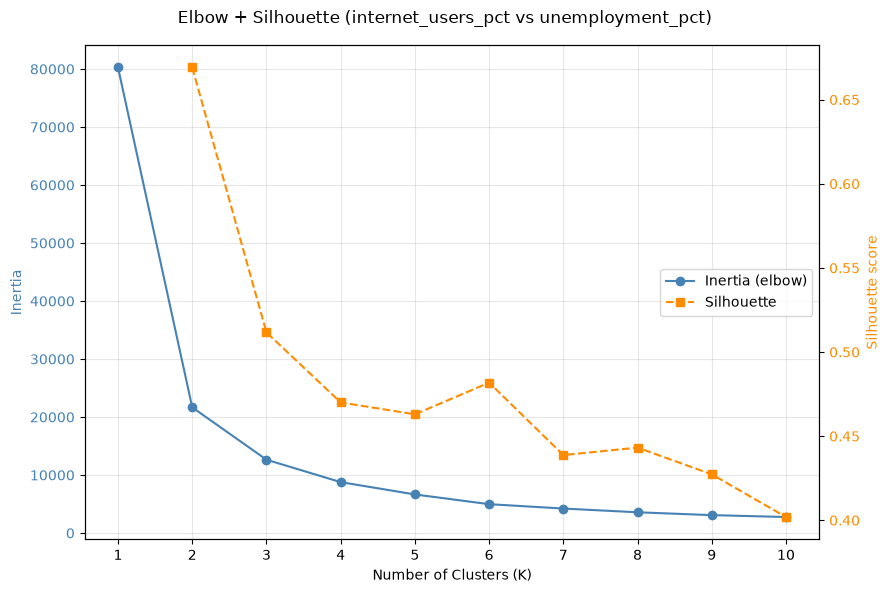

Elbow suggests:      K = 3
Silhouette suggests: K = 2   (best score = 0.669)
Full silhouette sweep: {2: 0.669, 3: 0.512, 4: 0.47, 5: 0.463, 6: 0.482, 7: 0.439, 8: 0.443, 9: 0.427, 10: 0.402}
→ Disagreement (elbow=3, silhouette=2). Defaulting to silhouette (quantitative separation metric). Inspect the plot and override manually if domain reasoning favours another K.


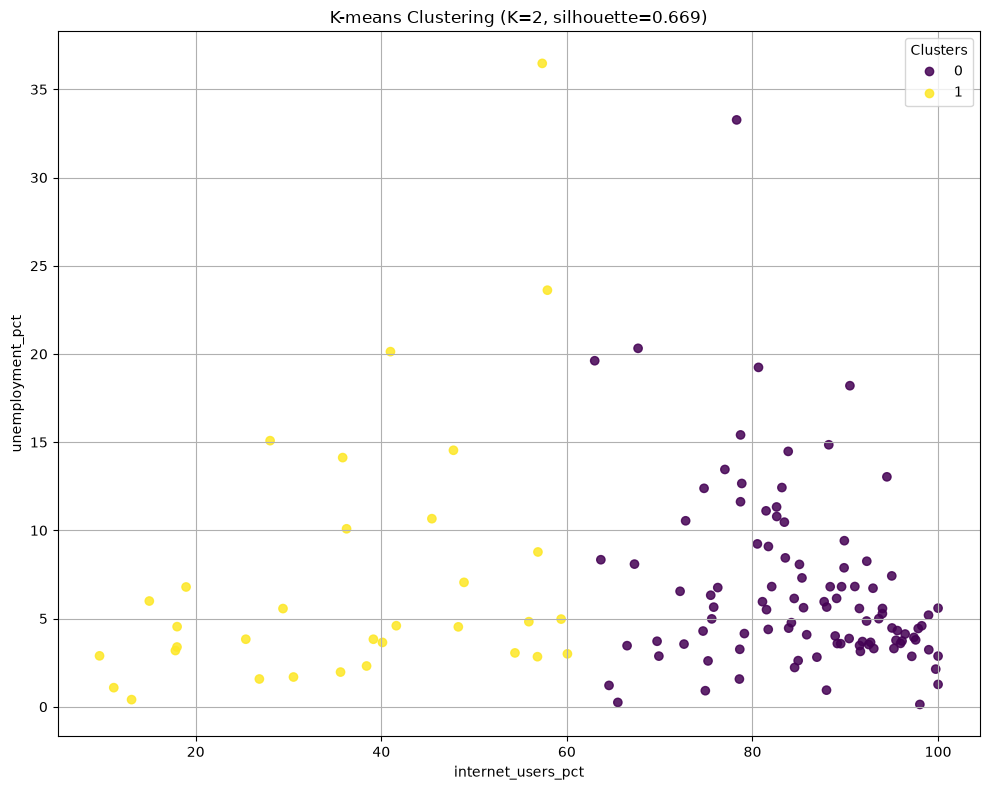

In [4]:
# --- 1. FEATURE SELECTION ---
features = list(lowest_corr_pair)
X = df_clustering[features]


# --- 2. FUNCTIONS: ELBOW AND SILHOUETTE ---

def find_elbow(inertia: list, min_k: int = 2) -> int:
    """
    Geometric elbow detection. Skips K < min_k because a single cluster has
    no analytical value and the K=1 -> K=2 inertia drop always dominates the
    geometry, producing a spurious 'K = 1' answer on flat curves.
    """
    k_vals = np.arange(1, len(inertia) + 1, dtype=float)
    coords = np.column_stack((k_vals, inertia))
    p1, p2 = coords[0], coords[-1]
    chord = p2 - p1
    chord /= np.linalg.norm(chord)
    ortho = np.array([-chord[1], chord[0]])
    distances = np.abs((coords - p1) @ ortho)
    distances[: min_k - 1] = -np.inf       # exclude K = 1 (and K < min_k)
    return int(k_vals[np.argmax(distances)])


def silhouette_sweep(X, k_values) -> dict:
    """
    Mean silhouette score for each K in k_values (K >= 2 only).
    Range: -1 .. 1. Higher = better separated & more compact clusters.
      > 0.50  strong structure
      0.25–0.50  moderate structure
      < 0.25  weak / no structure (a red flag for this feature pair)
    """
    scores = {}
    for k in k_values:
        if k < 2:
            continue                    # silhouette undefined for K = 1
        labels = KMeans(n_clusters=k, random_state=42, n_init=10).fit_predict(X)
        scores[k] = silhouette_score(X, labels)
    return scores


def find_optimal_k_by_silhouette(scores: dict) -> int:
    """Return the K that maximises the mean silhouette score."""
    return max(scores, key=scores.get)


# --- 3. RUN BOTH SWEEPS ---
k_values = list(range(1, 11))

inertia = []
for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10).fit(X)
    inertia.append(km.inertia_)

silhouette_scores = silhouette_sweep(X, k_values)


# --- 4. COMBINED PLOT ---
fig, ax1 = plt.subplots(figsize=(9, 6))

# Left axis: inertia (elbow)
ax1.plot(k_values, inertia, marker='o', color='steelblue', label='Inertia (elbow)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia', color='steelblue')
ax1.tick_params(axis='y', labelcolor='steelblue')
ax1.set_xticks(k_values)
ax1.grid(True, alpha=0.3)

# Right axis: silhouette
ax2 = ax1.twinx()
sil_ks = sorted(silhouette_scores)
sil_vals = [silhouette_scores[k] for k in sil_ks]
ax2.plot(sil_ks, sil_vals, marker='s', linestyle='--',
         color='darkorange', label='Silhouette')
ax2.set_ylabel('Silhouette score', color='darkorange')
ax2.tick_params(axis='y', labelcolor='darkorange')

# Combined legend
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc='center right')

fig.suptitle(f'Elbow + Silhouette ({features[0]} vs {features[1]})')
plt.tight_layout()
plt.savefig('elbow_silhouette_plot.png')
plt.show()
plt.close(fig)


# --- 5. COMBINE SIGNALS INTO A SINGLE DECISION ---
k_elbow = find_elbow(inertia, min_k=2)
k_sil   = find_optimal_k_by_silhouette(silhouette_scores)
best_sil = silhouette_scores[k_sil]

print(f"Elbow suggests:      K = {k_elbow}")
print(f"Silhouette suggests: K = {k_sil}   (best score = {best_sil:.3f})")
print("Full silhouette sweep:", {k: round(v, 3) for k, v in silhouette_scores.items()})

if k_elbow == k_sil:
    optimal_k = k_elbow
    print(f"→ Both methods agree: K = {optimal_k}.")
else:
    optimal_k = k_sil
    print(
        f"→ Disagreement (elbow={k_elbow}, silhouette={k_sil}). "
        f"Defaulting to silhouette (quantitative separation metric). "
        f"Inspect the plot and override manually if domain reasoning favours "
        f"another K."
    )

if best_sil < 0.25:
    print(
        "⚠  Best silhouette is below 0.25 → this feature pair does not cluster "
        "well. Expect diffuse clouds, not clean blobs. This is itself a valid "
        "analytical finding (see workshop Analysis question)."
    )

# Manual override example (uncomment to force a value):
# optimal_k = 3


# --- 6. K-MEANS EXECUTION ---
kmeans_model = KMeans(n_clusters=optimal_k, random_state=42, n_init=10)
cluster_labels = kmeans_model.fit_predict(X)
df_clustering = df_clustering.assign(cluster=cluster_labels)


# --- 7. VISUALIZATION ---
fig, ax = plt.subplots(figsize=(10, 8))
scatter = ax.scatter(
    X.iloc[:, 0],
    X.iloc[:, 1],
    c=cluster_labels,
    cmap='viridis',
    alpha=0.85,
)
ax.set_title(
    f'K-means Clustering (K={optimal_k}, '
    f'silhouette={silhouette_scores[optimal_k]:.3f})'
)
ax.set_xlabel(features[0])
ax.set_ylabel(features[1])
ax.legend(*scatter.legend_elements(), title="Clusters")
ax.grid(True)
plt.tight_layout()
plt.show()
plt.close(fig)


__Challenges (Workshop 3, part I):__
1. Organize the code of the example and complete the data pipeline: 
    - Use `try-except-finally` blocks as required 
    - Every individual process must be wrapped as a `task` using the corresponding decorator and its parameters when necessary. 
    - Create a `transform_data` task focused on data cleansing and preparation (variable selection/deletion)
    - Create a `load_data` task to create a table in a Dockerized PostgreSQL database and populate with with the clustering-oriented Dataframe
    - Invoke the tasks in the proper order in the `flow`
    - Use the `timing_decorator` to report the duration of each task
    - **Include the analytic part of this notebook (model selection, visualization) to implement an End-to-End pipeline (flow)**
1. Extend the filesystem report
    - Using the function `get_directory_size` (below), create a decorator to get and report the size of the downloaded dataset (size in bytes of the download folder)
    - Report the size in the previous question in a human readable unit
    - Use the attribute kmeans.cluster_centers_ and scatter plot to add the centroids of the best KMeans model (best K parameter) to the scatter plot
        - `centroids = kmeans.cluster_centers_`
1. Analysis
    - Based on the original data, justify the result of the selection of the  parameter K for the K-means method

In [5]:
def get_directory_size(path='.'):
    total_size = 0
    for dirpath, dirnames, filenames in os.walk(path):
        for f in filenames:
            # Create the full file path by joining the directory path and file name
            fp = os.path.join(dirpath, f)
            # Skip symbolic links to avoid counting them
            if not os.path.islink(fp):
                total_size += os.path.getsize(fp)
    return total_size    
